# 4. Landmark displacement

Is the facial motion the detectors respond to in the right place?

The two notebooks before this one score the detectors. This one checks
the stimuli instead, which is what makes those scores interpretable: a
low score could mean the detector failed, or it could mean the avatar
never moved its face the way the animation asked. Two things are asked
of the animations themselves.

**Consistency across avatars.** The same animation applied to four
different MetaHuman faces should move them in the same way. Each
avatar's landmark displacement trace is correlated with every other's,
per animation.

**Spatial correspondence with expected motion.** An animation for a
given action unit should move the landmarks that action unit is defined
over, and not the rest of the face. The mean displacement of the
targeted landmarks is divided by the mean of the others, which is 100
per cent when the animation shows no preference and above 100 when it
moves the targeted landmarks further.

Both read `derivatives/landmark-displacement/`, written by
`matlab/rigid_inverse_affine_transformation.m`, which removes head
motion before measuring displacement. Which landmarks each animation
targets comes from `sourcedata/AU_landm_mapping.mat`.

Produces Figure 4.

In [1]:
import os

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns

from au_detection_mh import analyses, utils

DATASET = os.path.join("..", "ds-au_detection_mh")
SOURCEDATA = os.path.join(DATASET, "sourcedata")
LANDMARKS = os.path.join(DATASET, "derivatives", "landmark-displacement")
RESULTS = os.path.join(DATASET, "derivatives", "au-detection-metrics")

# Activation above which a cell of the rig ground truth counts as an
# active action unit, and above which a detector counts as reporting
# one.  0.2 is the value the reported results use.
THRESHOLD = 0.2

# Avatar order used in the figures, which groups the two avatars the
# detectors did best on next to each other.
AVATAR_ORDER = ["Ada", "Pia", "Cooper", "Garry"]

# Manuscript figure styling
LABEL_FONTSIZE = 12
TICK_FONTSIZE = 10
DPI = 500
mpl.rcParams["font.size"] = 10

## Consistency across avatars

One row per ordered avatar pair per animation, so each unordered pair
appears twice; `drop_mirrored_pairs` keeps one of each.

In [2]:
corr_df = analyses.pairwise_landmark_correlations(LANDMARKS)
print("ordered pairs:", len(corr_df))
corr_df.head()

ordered pairs: 216


,Animation,Avatar_0,Avatar_1,pearsonr,Pairs
0,AU01,Ada,Garry,0.951251,Ada_Garry
1,AU01,Ada,Cooper,0.978221,Ada_Cooper
2,AU01,Ada,Pia,0.968373,Ada_Pia
3,AU01,Garry,Ada,0.951251,Garry_Ada
4,AU01,Garry,Cooper,0.962165,Garry_Cooper


In [3]:
unique_pairs_df = analyses.drop_mirrored_pairs(corr_df)
print("unordered pairs:", len(unique_pairs_df))
print(sorted(unique_pairs_df["Pairs"].unique()))
unique_pairs_df.head()

unordered pairs: 108
['Ada_Cooper', 'Ada_Garry', 'Ada_Pia', 'Cooper_Pia', 'Garry_Cooper', 'Garry_Pia']


,Animation,Avatar_0,Avatar_1,pearsonr,Pairs
0,AU01,Ada,Garry,0.951251,Ada_Garry
1,AU01,Ada,Cooper,0.978221,Ada_Cooper
2,AU01,Ada,Pia,0.968373,Ada_Pia
3,AU01,Garry,Cooper,0.962165,Garry_Cooper
4,AU01,Garry,Pia,0.942222,Garry_Pia


In [4]:
unique_pairs_df["pearsonr"] = unique_pairs_df["pearsonr"].astype(float)
for column in ["Animation", "Avatar_0", "Avatar_1", "Pairs"]:
    unique_pairs_df[column] = unique_pairs_df[column].astype("category")

unique_pairs_df.groupby("Pairs", observed=True)["pearsonr"].describe()

,count,mean,std,min,25%,50%,75%,max
Pairs,,,,,,,,
Ada_Cooper,18.0,0.876833,0.175808,0.228166,0.876102,0.933756,0.958835,0.985375
Ada_Garry,18.0,0.811948,0.162991,0.373627,0.771834,0.848248,0.940037,0.976061
Ada_Pia,18.0,0.902367,0.106663,0.511582,0.895497,0.925974,0.954999,0.985304
Cooper_Pia,18.0,0.909461,0.073379,0.738461,0.875156,0.924019,0.960597,0.986228
Garry_Cooper,18.0,0.882766,0.105493,0.670820,0.805707,0.934703,0.960082,0.989708
Garry_Pia,18.0,0.826127,0.137899,0.465158,0.806584,0.848953,0.927533,0.977314


### Within-factor comparisons

Across avatar pairs, then across animations.

In [5]:
def friedman_within(data, dv, within, subject, label):
    result = pg.friedman(data=data, dv=dv, within=within,
                         subject=subject)
    corrected = 0.05 / len(data[within].unique())
    print(f"Friedman's test for {label} across {within}:")
    print(result)
    print(f"Less than the corrected p-val (p/N = {corrected:.4f})? = "
          f"{result['p_unc'].values[0] < corrected}\n")
    return result


friedman_within(unique_pairs_df, "pearsonr", "Pairs", "Animation",
                "pairwise corr between avatars")

Friedman's test for pairwise corr between avatars across Pairs:
         Source         W  ddof1          Q         p_unc
Friedman  Pairs  0.483951      5  43.555556  2.850832e-08
Less than the corrected p-val (p/N = 0.0083)? = True



,Source,W,ddof1,Q,p_unc
Friedman,Pairs,0.483951,5,43.555556,2.850832e-08


In [6]:
(unique_pairs_df.groupby("Animation", observed=True)["pearsonr"]
 .describe().sort_values("mean", ascending=False))

,count,mean,std,min,25%,50%,75%,max
Animation,,,,,,,,
AU12,6.0,0.982268,0.007168,0.970933,0.978372,0.985340,0.986015,0.989708
browsAU10,6.0,0.975010,0.011565,0.958794,0.966248,0.981239,0.982658,0.984407
AU02,6.0,0.967274,0.018513,0.941515,0.955839,0.967303,0.983690,0.986350
AU01,6.0,0.962089,0.013262,0.942222,0.953979,0.965269,0.969819,0.978221
AU10,6.0,0.953581,0.012530,0.935602,0.944792,0.958047,0.961005,0.967427
AU14,6.0,0.946975,0.031426,0.887710,0.948659,0.951401,0.959894,0.980870
browsAU12,6.0,0.922623,0.038156,0.861502,0.901013,0.941775,0.949357,0.951376
browsAll,6.0,0.913187,0.042029,0.850201,0.885624,0.925021,0.945670,0.953835
browsAU23,6.0,0.899664,0.042689,0.844795,0.862974,0.918903,0.931701,0.935087


In [7]:
friedman_within(unique_pairs_df, "pearsonr", "Animation", "Pairs",
                "pairwise corr between animations")

Friedman's test for pairwise corr between animations across Animation:
             Source         W  ddof1          Q         p_unc
Friedman  Animation  0.925582     17  94.409357  9.553377e-13
Less than the corrected p-val (p/N = 0.0028)? = True



,Source,W,ddof1,Q,p_unc
Friedman,Animation,0.925582,17,94.409357,9.553377e-13


## Spatial correspondence with expected motion

`active_inactive_ratio` is the mean displacement of the landmarks the
animation targets over the mean of the rest, as a percentage.

In [8]:
landmark_targets = utils.load_landmark_mapping(SOURCEDATA)
print(f"{len(landmark_targets)} animations in the mapping")
print("AU01 targets landmarks:", landmark_targets["AU01"])

18 animations in the mapping
AU01 targets landmarks: [0 1 2 3 4 5 6 7 8 9]


In [9]:
# Animation in the outer loop and avatar in the inner one, which is
# the row order the committed table was written in, so that
# regenerating it does not reorder the file.
ratio_rows = []
for animation in utils.ANIMATIONS:
    for avatar in utils.AVATARS:
        displacement = utils.load_landmark_displacement(
            LANDMARKS, avatar, animation)
        ratio_rows.append({
            "Avatar": avatar,
            "Animation": animation,
            "Mean_accuracy_perc": analyses.active_inactive_ratio(
                displacement, landmark_targets[animation]),
        })

landm_actv_over_inactv_df = pd.DataFrame(ratio_rows)
landm_actv_over_inactv_df.to_csv(
    os.path.join(RESULTS,
                 "mean_scaled_act_inactv_percentage_landm_ratio.csv"),
    index=False)
landm_actv_over_inactv_df.head()

,Avatar,Animation,Mean_accuracy_perc
0,Ada,AU01,301.080819
1,Garry,AU01,272.993843
2,Cooper,AU01,304.818181
3,Pia,AU01,291.946257
4,Ada,AU02,400.346122


In [10]:
# Reported as a ratio rather than a percentage
landm_actv_over_inactv_df["Mean_acc_reported"] = (
    landm_actv_over_inactv_df["Mean_accuracy_perc"] / 100)
landm_actv_over_inactv_df = landm_actv_over_inactv_df.drop(
    "Mean_accuracy_perc", axis=1)
landm_actv_over_inactv_df.head()

,Avatar,Animation,Mean_acc_reported
0,Ada,AU01,3.010808
1,Garry,AU01,2.729938
2,Cooper,AU01,3.048182
3,Pia,AU01,2.919463
4,Ada,AU02,4.003461


### Within-factor comparisons

In [11]:
(landm_actv_over_inactv_df.groupby("Avatar").describe()
 .map("{:,.2f}".format))

Mean_acc_reported                                          
                   count  mean   std   min   25%   50%   75%   max
Avatar                                                            
Ada                18.00  2.01  0.79  0.62  1.54  1.92  2.48  4.00
Cooper             18.00  1.93  0.71  0.97  1.52  1.67  2.38  3.74
Garry              18.00  1.88  0.66  1.00  1.45  1.64  2.32  3.28
Pia                18.00  1.93  0.68  1.17  1.46  1.76  2.12  3.85

In [12]:
friedman_within(landm_actv_over_inactv_df, "Mean_acc_reported",
                "Avatar", "Animation", "displacement ratio")

Friedman's test for displacement ratio across Avatar:
          Source         W  ddof1         Q    p_unc
Friedman  Avatar  0.095062      3  5.133333  0.16229
Less than the corrected p-val (p/N = 0.0125)? = False



,Source,W,ddof1,Q,p_unc
Friedman,Avatar,0.095062,3,5.133333,0.16229


In [13]:
(landm_actv_over_inactv_df.groupby("Animation").describe()
 .map("{:,.2f}".format))

Mean_acc_reported                                          
                      count  mean   std   min   25%   50%   75%   max
Animation                                                            
AU01                   4.00  2.93  0.14  2.73  2.87  2.97  3.02  3.05
AU02                   4.00  3.72  0.31  3.28  3.62  3.80  3.89  4.00
AU04                   4.00  2.72  0.12  2.58  2.66  2.73  2.79  2.85
AU06                   4.00  1.48  0.17  1.27  1.38  1.49  1.59  1.66
AU07                   4.00  1.30  0.47  0.62  1.20  1.45  1.56  1.68
AU10                   4.00  2.37  0.23  2.19  2.19  2.32  2.50  2.66
AU12                   4.00  2.51  0.30  2.22  2.28  2.47  2.69  2.86
AU14                   4.00  2.22  0.34  1.78  2.08  2.27  2.42  2.57
AU15                   4.00  1.66  0.38  1.22  1.46  1.65  1.85  2.13
AU17                   4.00  1.63  0.12  1.51  1.57  1.60  1.66  1.79
AU23                   4.00  1.69  0.23  1.43  1.54  1.68  1.83  1.96
browsAU10              4.00  1.87  0.03  1.83  1.85  1.87  1.89  1.89
browsAU12              4.00  1.76  0.19  1.63  1.66  1.69  1.78  2.03
browsAU14              4.00  1.70  0.23  1.43  1.55  1.74  1.89  1.89
browsAU15              4.00  1.42  0.07  1.33  1.39  1.42  1.44  1.51
browsAU17              4.00  1.61  0.08  1.50  1.57  1.63  1.67  1.68
browsAU23              4.00  1.26  0.08  1.18  1.20  1.26  1.32  1.35
browsAll               4.00  1.04  0.09  0.97  0.99  1.00  1.04  1.17

In [14]:
friedman_within(landm_actv_over_inactv_df, "Mean_acc_reported",
                "Animation", "Avatar", "displacement ratio")

Friedman's test for displacement ratio across Animation:
             Source         W  ddof1          Q     p_unc
Friedman  Animation  0.859907     17  58.473684  0.000002
Less than the corrected p-val (p/N = 0.0028)? = True



,Source,W,ddof1,Q,p_unc
Friedman,Animation,0.859907,17,58.473684,0.000002


### Figure 4: landmark displacement

4B is the between-avatar consistency as a lower-triangular colour map,
the upper triangle being masked because it mirrors the lower one. 4C is
the consistency per animation, and 4D the displacement ratio per
animation, with the dashed line at a ratio of 1, where the targeted and
the other landmarks move equally far.

In [15]:
summary_df = unique_pairs_df.groupby("Pairs", observed=True).describe()

# Lower triangle, read down the rows: Ada against each of the other
# three, then Pia against the two below it, then Cooper against Pia
PAIR_GRID = ["Ada_Garry", "Ada_Cooper", "Ada_Pia",
             "Garry_Pia", "Cooper_Pia",
             "Garry_Cooper"]
y_tick_labels = ["Ada", "Pia", "Cooper"]
x_tick_labels = ["Garry", "Cooper", "Pia"]

mask = np.array(((1, 1, 1), (1, 1, 0), (1, 0, 0)))
color_map = mask.astype(float)
color_map[mask == 1] = [summary_df[("pearsonr", "mean")][pair]
                        for pair in PAIR_GRID]
print(color_map)

[[0.81194795 0.87683274 0.90236681]
 [0.82612666 0.90946064 0.        ]
 [0.88276583 0.         0.        ]]


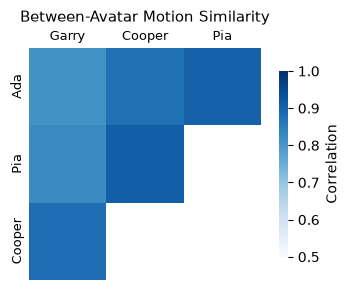

In [16]:
fig, ax = plt.subplots(figsize=(4, 3))
sns.heatmap(color_map, cmap="Blues", vmin=0.5, vmax=1, square=True,
            linewidth=0,
            cbar_kws={"label": "Correlation", "shrink": 0.8},
            mask=mask == 0, ax=ax)
ax.set_title("Between-Avatar Motion Similarity", fontsize=11)
ax.set_xticklabels(x_tick_labels)
ax.set_yticklabels(y_tick_labels)
ax.xaxis.tick_top()
ax.tick_params(axis="both", length=0, labelsize=9)
fig.tight_layout()
fig.savefig(
    os.path.join(RESULTS,
                 "Figure4B_landm_CrossCorr_avatars_heatmap_annot_blues.svg"),
    dpi=DPI)
plt.show()

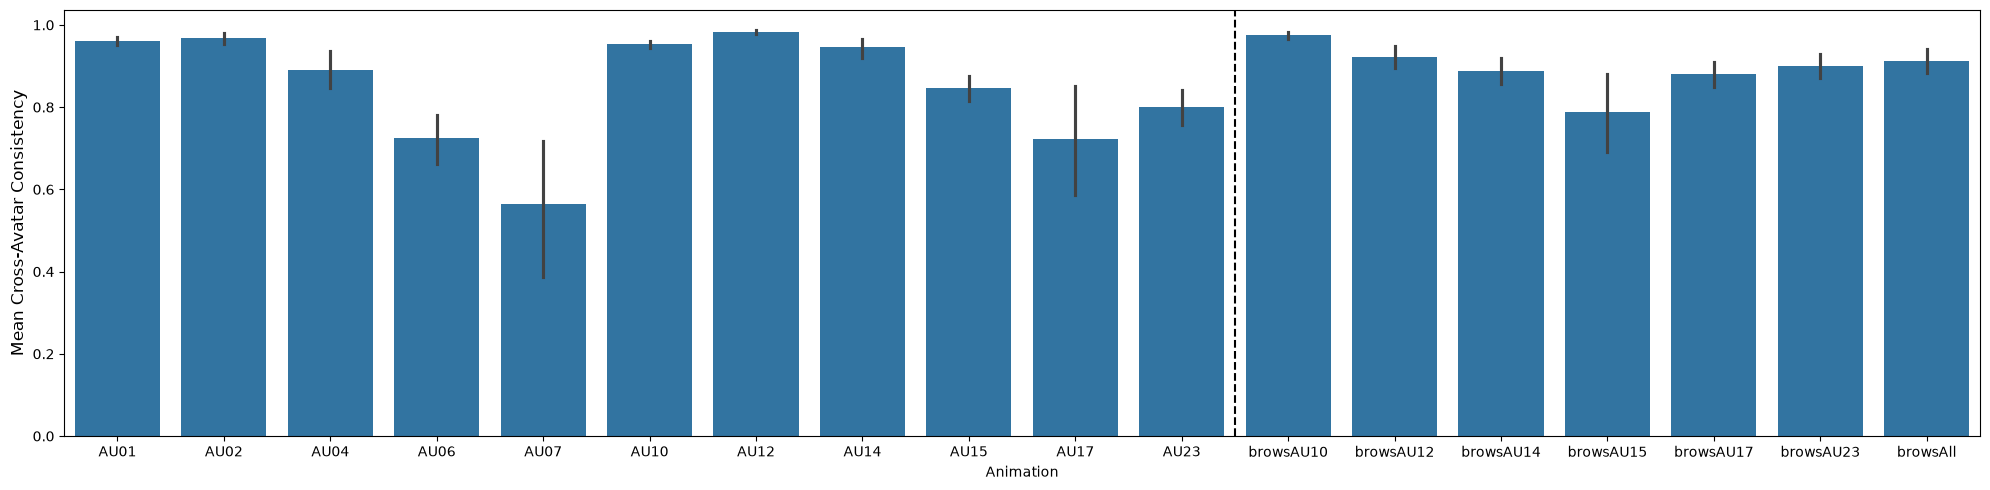

In [17]:
fig, ax = plt.subplots(figsize=(20, 5))
sns.barplot(unique_pairs_df, x="Animation", y="pearsonr", ax=ax)
ax.set_ylabel("Mean Cross-Avatar Consistency", fontsize=LABEL_FONTSIZE)
ax.axvline(x=10.5, color="black", ls="--")
fig.tight_layout()
fig.savefig(
    os.path.join(RESULTS,
                 "Figure4C_animation_consistency_barplot_ci.svg"),
    dpi=DPI)
plt.show()

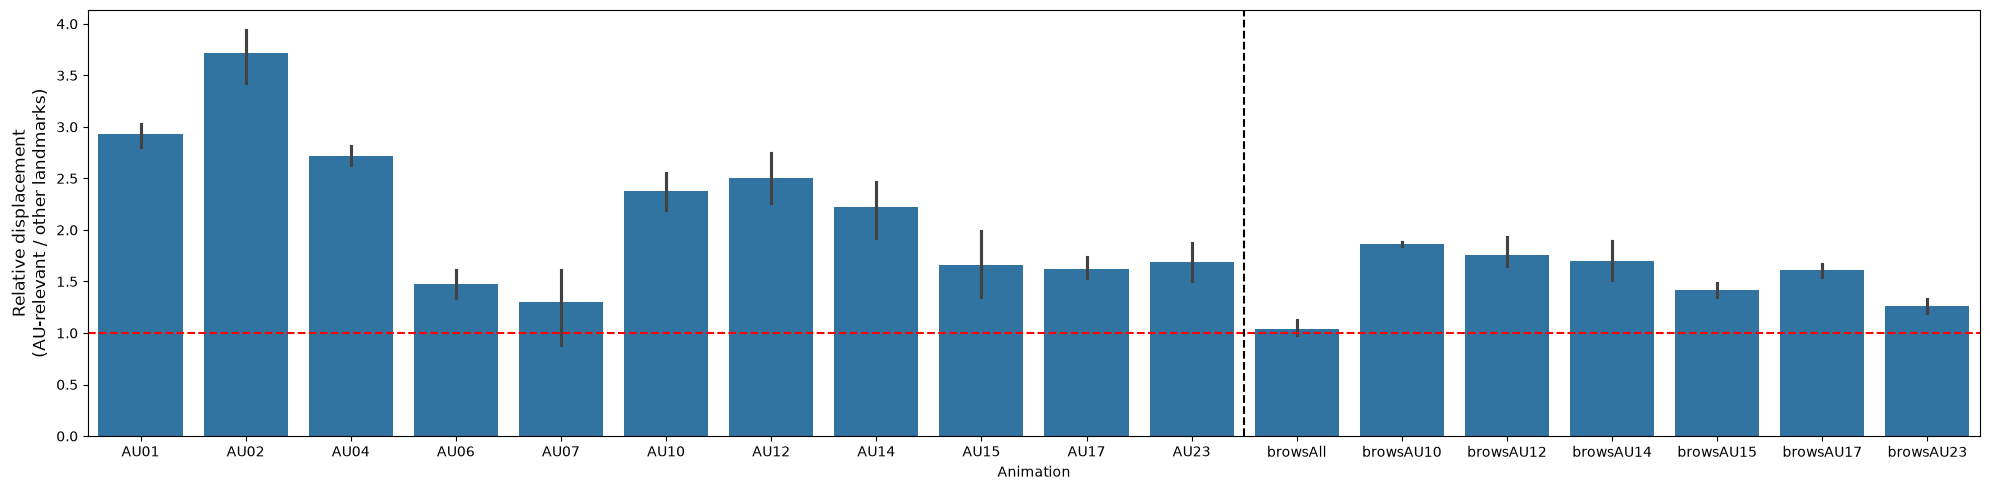

In [18]:
fig, ax = plt.subplots(figsize=(20, 5))
sns.barplot(landm_actv_over_inactv_df, x="Animation",
            y="Mean_acc_reported", ax=ax)
ax.set_ylabel("Relative displacement\n"
              "(AU-relevant / other landmarks)",
              fontsize=LABEL_FONTSIZE)
ax.axhline(y=1, color="r", ls="--")
ax.axvline(x=10.5, color="black", ls="--")
fig.tight_layout()
fig.savefig(os.path.join(RESULTS, "Figure4D_acc_ratio_barplot.svg"),
            dpi=DPI)
plt.show()